In [1]:
%pip install -q xgboost optuna shap scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
random_seed = 42+2
warnings.filterwarnings('ignore', message='Skipping features without any observed values')

In [3]:
from sklearn.datasets import fetch_openml

data = fetch_openml(name="anneal", version = 1, as_frame=True)
X, y = data.data, data.target

In [4]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 38 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   family                        126 non-null    category
 1   product-type                  898 non-null    category
 2   steel                         812 non-null    category
 3   carbon                        898 non-null    int64   
 4   hardness                      898 non-null    int64   
 5   temper_rolling                137 non-null    category
 6   condition                     595 non-null    category
 7   formability                   580 non-null    category
 8   strength                      898 non-null    int64   
 9   non-ageing                    105 non-null    category
 10  surface-finish                9 non-null      category
 11  surface-quality               654 non-null    category
 12  enamelability                 16 non-null     category
 13  b

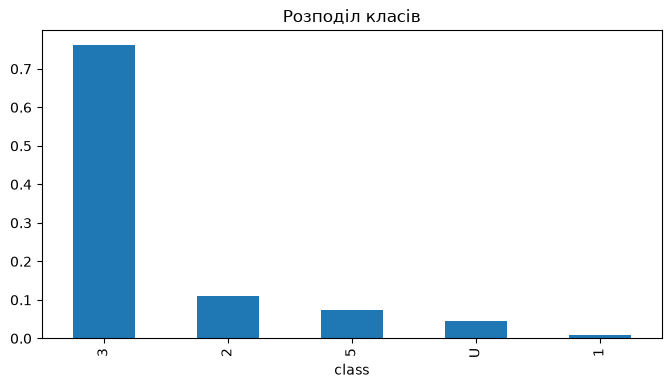

In [5]:
y.value_counts().apply(lambda c: c / len(y)).plot(kind='bar', figsize=(8, 4))
plt.title("Розподіл класів")
plt.show()

Спостерігається дуже сильний дисбаланс класів

In [6]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 38 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   family                        126 non-null    category
 1   product-type                  898 non-null    category
 2   steel                         812 non-null    category
 3   carbon                        898 non-null    int64   
 4   hardness                      898 non-null    int64   
 5   temper_rolling                137 non-null    category
 6   condition                     595 non-null    category
 7   formability                   580 non-null    category
 8   strength                      898 non-null    int64   
 9   non-ageing                    105 non-null    category
 10  surface-finish                9 non-null      category
 11  surface-quality               654 non-null    category
 12  enamelability                 16 non-null     category
 13  b

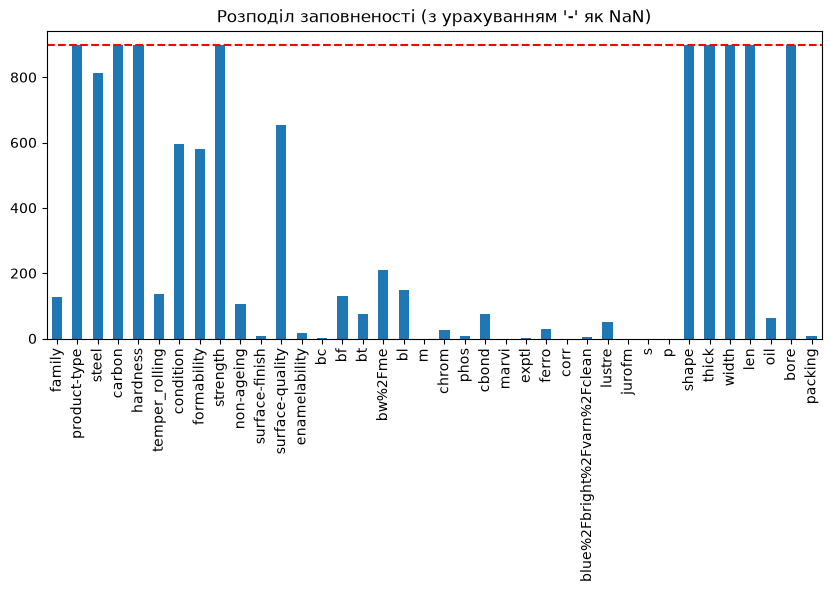

In [7]:
X_fixed = X.replace('-', np.nan)
X_fixed.isna().sum().apply(lambda el: len(X) - el).plot(kind='bar', figsize=(10, 4))
plt.title("Розподіл заповненості (з урахуванням '-' як NaN)")
plt.axhline(y=len(X), color='r', linestyle='--')
plt.show()

In [8]:
all_nan = X.columns[X.isna().all()].tolist()

constant = [c for c in X.columns if X[c].nunique(dropna=True) <= 1]

MIN_NON_NULL = 10
almost_empty = X.columns[X.notna().sum() < MIN_NON_NULL].tolist()

to_drop = sorted(set(all_nan) | set(constant) | set(almost_empty))
print("Повністю порожні:", all_nan)
print("Константні:", constant)
print("Майже порожні (< 10 значень):", almost_empty)

X_cleaned = X.drop(columns=to_drop)

Повністю порожні: ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Константні: ['product-type', 'temper_rolling', 'non-ageing', 'surface-finish', 'bc', 'bf', 'bt', 'bl', 'm', 'chrom', 'phos', 'cbond', 'marvi', 'exptl', 'ferro', 'corr', 'lustre', 'jurofm', 's', 'p']
Майже порожні (< 10 значень): ['surface-finish', 'bc', 'm', 'phos', 'marvi', 'exptl', 'corr', 'blue%2Fbright%2Fvarn%2Fclean', 'jurofm', 's', 'p', 'packing']


In [9]:
X_cleaned.columns

Index(['family', 'steel', 'carbon', 'hardness', 'condition', 'formability',
       'strength', 'surface-quality', 'enamelability', 'bw%2Fme', 'shape',
       'thick', 'width', 'len', 'oil', 'bore'],
      dtype='str')

In [10]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

def perm_chi2_pvalue(missing, y_codes, n_perm=10000, seed=random_seed):
    """Перестановковий тест незалежності 'пропуск × клас' (статистика χ²)."""
    rng = np.random.default_rng(seed)
    n = len(missing)
    k = y_codes.max() + 1
    class_tot = np.bincount(y_codes, minlength=k)
    n_miss = missing.sum()
    exp1 = n_miss * class_tot / n          
    exp0 = (n - n_miss) * class_tot / n   

    def stat(m):
        o1 = np.bincount(y_codes[m == 1], minlength=k)
        o0 = class_tot - o1
        return ((o1 - exp1) ** 2 / exp1).sum() + ((o0 - exp0) ** 2 / exp0).sum()

    obs = stat(missing)
    cnt = sum(stat(rng.permutation(missing)) >= obs for _ in range(n_perm))
    return (cnt + 1) / (n_perm + 1)

y_codes = pd.factorize(pd.Series(np.asarray(y)))[0]

missing_ratios = X_cleaned.isna().mean().sort_values(ascending=False)
top_missing_features = missing_ratios[missing_ratios > .5].index.tolist()
print("Обрані ознаки з найбільшою часткою пропусків:", top_missing_features)

results = []
for feature in top_missing_features:
    missing_indicator = X_cleaned[feature].isna().astype(int).values
    table = pd.crosstab(missing_indicator, y_codes)

    chi2, p_chi2, dof, expected = chi2_contingency(table)
    low_share = (expected < 5).mean()

    if low_share > 0.2 or expected.min() < 1:
        p_val = perm_chi2_pvalue(missing_indicator, y_codes)
        method = "permutation"
    else:
        p_val = p_chi2
        method = "chi2"

    results.append({
        'Feature': feature,
        'Missing_Ratio': missing_ratios[feature],
        'Chi2_Stat': chi2,
        'Low_Expected_Share': low_share,
        'Method': method,
        'p-value': p_val,
    })

results_df = pd.DataFrame(results)
print(results_df.to_string())

Обрані ознаки з найбільшою часткою пропусків: ['enamelability', 'oil', 'family', 'bw%2Fme']
         Feature  Missing_Ratio   Chi2_Stat  Low_Expected_Share       Method       p-value
0  enamelability       0.982183   44.437628                 0.4  permutation  3.999600e-04
1            oil       0.928731   24.528546                 0.3  permutation  1.599840e-03
2         family       0.859688  463.747626                 0.1         chi2  4.630236e-99
3        bw%2Fme       0.765033   13.661391                 0.1         chi2  8.457987e-03


З тестів можна побачити, що колонки які є доволі розрідженими відхиляють 0-теорію, тобто фічі і цільова колонка є залежними та вони не є MCAR, тобто не потребують видалення.

In [11]:
from sklearn.preprocessing import LabelEncoder
ley = LabelEncoder()
y = ley.fit_transform(y)

In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_cleaned, y, test_size=0.2, stratify=y, random_state=random_seed)
print(X_train.shape, X_test.shape)

(718, 16) (180, 16)


In [13]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    """Імпутація + OHE (+ індикатори пропусків для варіанта B). Усе всередині Pipeline -> без leakage."""
    transformers = [
        ('num', SimpleImputer(strategy='median'),
          make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'),
             make_column_selector()))
    return ColumnTransformer(transformers)

def build_pipeline(callback, with_indicators=True, params=None):
    """Єдина точка створення моделі: фіксований seed, паралелізм для RF/XGB, мерж гіперпараметрів."""
    p = {'random_state': random_seed}
    if callback.__name__ == 'RandomForestClassifier' or callback.__name__ == 'XGBClassifier':
        p['n_jobs'] = -1
    if callback.__name__ == 'XGBClassifier':
        p['eval_metric'] = 'mlogloss'
    p.update(params or {})
    return Pipeline([('prep', build_preprocessor(with_indicators)),
                     ('clf', callback(**p))])

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

In [15]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

scoring = {'acc': 'accuracy', 'fim': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=random_seed)


In [16]:
MODELS = {'DT': DecisionTreeClassifier, 'RF': RandomForestClassifier, 'XGB': XGBClassifier}
VARIANTS = {'A': False, 'B': True}   # A – без індикаторів пропусків, B – з індикаторами

cv_res = {}
for m_name, cls in MODELS.items():
    for v_name, flag in VARIANTS.items():
        cv_res[(m_name, v_name)] = pd.DataFrame(cross_validate(
            build_pipeline(cls, with_indicators=flag),
            X_train, y_train, cv=cv, scoring=scoring))

### 3.2 Результати крос-валідації (RepeatedStratifiedKFold 5×3, середнє ± std по 15 значеннях)
Однакові спліти (`cv` з фіксованим `random_state`) використані для всіх моделей і обох варіантів – це потрібно для парного t-тесту
* **Варіант A** – імпутація без індикаторів пропусків.
* **Варіант B** – імпутація + `MissingIndicator`.

In [17]:
def fmt(s): return f"{s.mean():.3f} ± {s.std():.3f}"

def summary_table(variant):
    rows = {}
    for m_name in MODELS:
        df = cv_res[(m_name, variant)]
        rows[m_name] = {'accuracy': fmt(df['test_acc']),
                        'f1_macro': fmt(df['test_fim']),
                        'balanced_acc': fmt(df['test_bacc']),
                        'fit_time, s': fmt(df['fit_time'])}
    return pd.DataFrame(rows).T

print('Таблиця 1. Варіант A (без індикаторів пропусків)')
display(summary_table('A'))
print('Таблиця 2. Варіант B (з індикаторами пропусків)')
display(summary_table('B'))

Таблиця 1. Варіант A (без індикаторів пропусків)


,accuracy,f1_macro,balanced_acc,"fit_time, s"
DT,0.953 ± 0.018,0.895 ± 0.091,0.896 ± 0.092,0.026 ± 0.006
RF,0.943 ± 0.016,0.898 ± 0.076,0.888 ± 0.069,0.251 ± 0.027
XGB,0.947 ± 0.016,0.878 ± 0.088,0.871 ± 0.088,0.447 ± 0.090


Таблиця 2. Варіант B (з індикаторами пропусків)


,accuracy,f1_macro,balanced_acc,"fit_time, s"
DT,0.991 ± 0.007,0.942 ± 0.080,0.943 ± 0.081,0.030 ± 0.004
RF,0.993 ± 0.006,0.959 ± 0.072,0.952 ± 0.075,0.259 ± 0.043
XGB,0.987 ± 0.009,0.921 ± 0.088,0.920 ± 0.089,0.455 ± 0.255


Індикатори пропусків (варіант B) підвищили всі метрики для всіх трьох моделей: macro F1 зріс для DT з 0,895 до 0,942, для RF з 0,898 до 0,959, для XGB з 0,878 до 0,921. Приріст узгоджений за моделями й метриками, що відповідає аналізу пропусків: для більшості ознак пропуск залежить від класу (не MCAR), тож сам факт пропуску несе інформацію про клас. Серед моделей варіанта B найвище середнє macro F1 має RF (0,959 ± 0,072), проте різниця з DT (0,942 ± 0,080) мала порівняно з розкидом, який зумовлений рідкісними класами.

In [ ]:
import optuna
from sklearn.model_selection import StratifiedKFold, cross_val_score
warnings.filterwarnings('ignore', category=optuna.exceptions.ExperimentalWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_TRIALS = 20 
def suggest_params(trial, cls):
    if cls is DecisionTreeClassifier:
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if cls is RandomForestClassifier:
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    if cls is XGBClassifier:
        return {
            'n_estimators': trial.suggest_int('n_estimators', 50, 400),
            'max_depth': trial.suggest_int('max_depth', 2, 10),
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
            'subsample': trial.suggest_float('subsample', 0.6, 1.0),
            'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
            'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
        }
    raise ValueError(cls)


def tune(cls, X_tr, y_tr, n_trials=N_TRIALS):
    """Optuna (TPE) з внутрішньою 3-fold CV по f1_macro. Повертає study."""
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=random_seed)
    def objective(trial):
        pipe = build_pipeline(cls, True, suggest_params(trial, cls))
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()
    study = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=random_seed))
    study.optimize(objective, n_trials=n_trials)
    return study

### 3.3 Налаштування гіперпараметрів: Optuna + nested CV
* Внутрішній цикл – Optuna (TPE, `seed=44`) з 3-fold CV по `f1_macro`.
* Зовнішній цикл – 5-fold: на кожному зовнішньому train-фолді підбираємо параметри, на зовнішньому валідаційному – оцінюємо. Це **неупереджена** оцінка якості «процедури налаштування».
* `best_value` з `study` – оцінка на тих самих даних, за якими вибирали параметри, тому вона **оптимістична**; різницю з nested показує стовпчик `gap`.

In [19]:
from sklearn.metrics import f1_score
import time

outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_seed)
nested = {}
studies = {}
t0 = time.time()
for m_name, cls in MODELS.items():
    scores = []
    for tr_idx, va_idx in outer.split(X_train, y_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        st = tune(cls, X_tr, y_tr)
        mdl = build_pipeline(cls, True, st.best_params).fit(X_tr, y_tr)
        scores.append(f1_score(y_va, mdl.predict(X_va), average='macro'))
    nested[m_name] = np.array(scores)
    studies[m_name] = tune(cls, X_train, y_train)
    print(f'{m_name} done, {time.time()-t0:.0f}s')

DT done, 13s
RF done, 298s
XGB done, 677s


In [20]:
rows = {}
for m_name in MODELS:
    ns = nested[m_name]
    rows[m_name] = {'nested f1_macro': fmt(pd.Series(ns)),
                    'best_value (inner CV)': round(studies[m_name].best_value, 3),
                    'gap': round(studies[m_name].best_value - ns.mean(), 3)}
print('Таблиця 3. Nested CV vs best_value')
display(pd.DataFrame(rows).T)

Таблиця 3. Nested CV vs best_value


,nested f1_macro,best_value (inner CV),gap
DT,0.902 ± 0.124,0.963,0.061
RF,0.951 ± 0.086,0.961,0.01
XGB,0.944 ± 0.087,0.917,-0.027


Якщо проаналізувати результати, то можна побачити,що жодна найкраща модель не є реально кращою за моделі nested, а лише є сильніше навченою на шумах.

Таблиця 4. Найкращі гіперпараметри (Optuna, весь train)


,max_depth,min_samples_split,min_samples_leaf,class_weight,n_estimators,max_features,learning_rate,subsample,colsample_bytree,min_child_weight
DT,10.0,7.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RF,20,NaN,1,balanced,250,sqrt,NaN,NaN,NaN,NaN
XGB,9.0,NaN,NaN,NaN,245.0,NaN,0.033423,0.808663,0.873769,1.014767


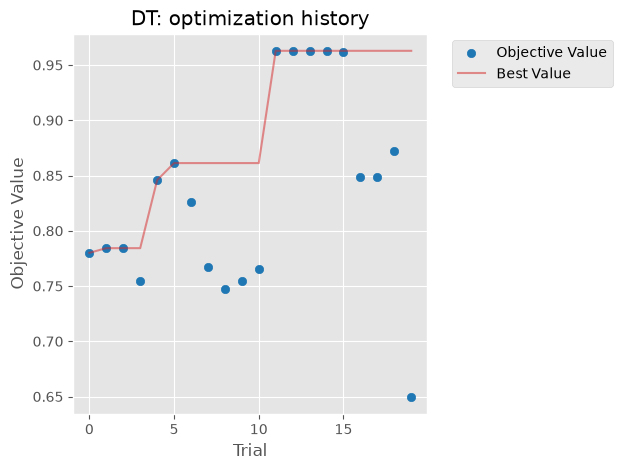

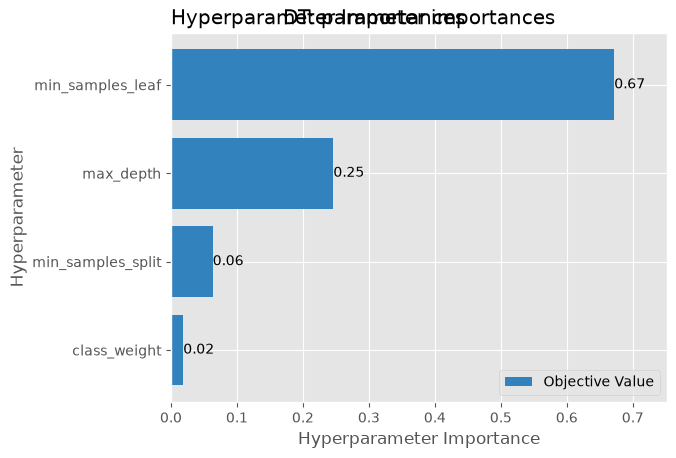

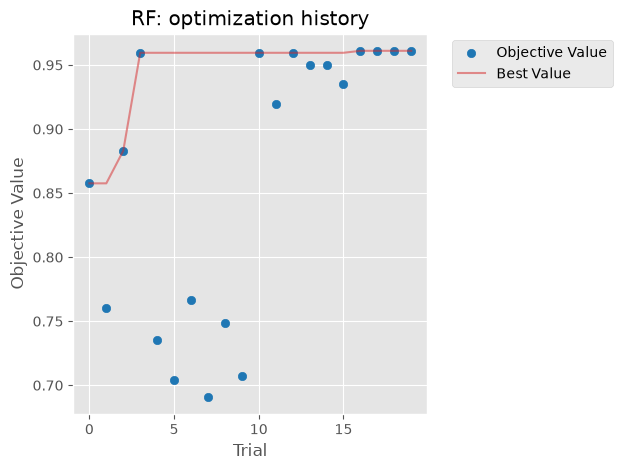

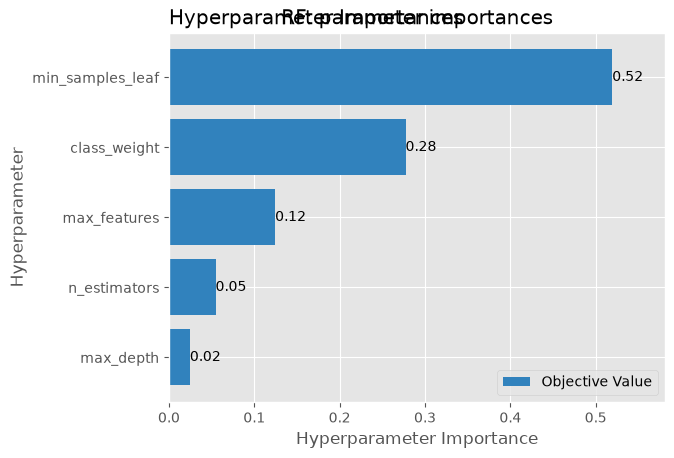

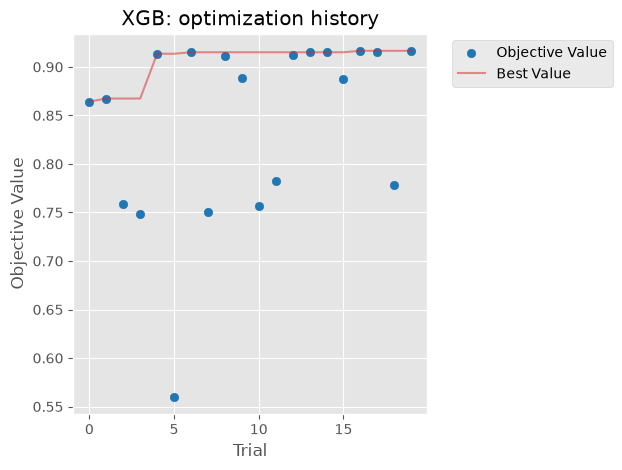

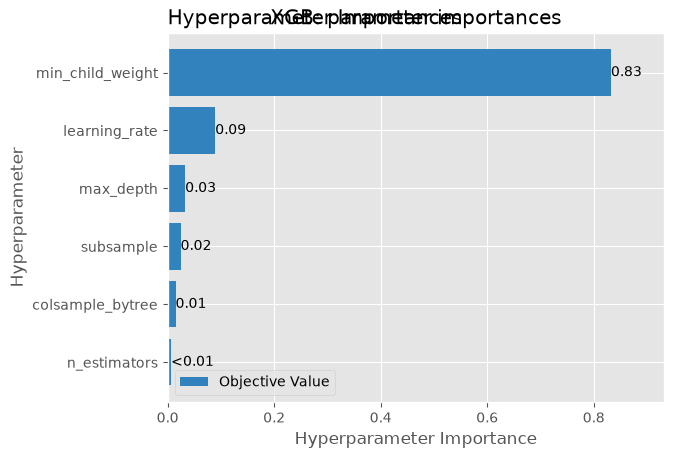

In [21]:
best_params = pd.DataFrame({m: studies[m].best_params for m in MODELS}).T
print('Таблиця 4. Найкращі гіперпараметри (Optuna, весь train)')
display(best_params)

final = {m: build_pipeline(cls, True, studies[m].best_params).fit(X_train, y_train)
         for m, cls in MODELS.items()}

for m_name in MODELS:
    ax = optuna.visualization.matplotlib.plot_optimization_history(studies[m_name])
    ax.set_title(f'{m_name}: optimization history'); plt.show()
    ax = optuna.visualization.matplotlib.plot_param_importances(studies[m_name])
    ax.set_title(f'{m_name}: parameter importances'); plt.show()

Для RF і XGB найкраще значення цільової функції досягнуто швидко (приблизно за 3-4 спроби), далі воно змінюється мало, тож пошук вийшов на плато. Для DT стрибок до ≈0,96 стався лише на 11-й спробі, тому збіжність підтверджена слабше. Найважливішим гіперпараметром у DT (0,69) і RF (0,66) є min_samples_leaf, у XGB min_child_weight (0,83): обидва задають мінімальний обсяг даних у листку, що за сильного дисбалансу критично для рідкісних класів (надмірно великі значення не дозволяють виділити такі класи й різко знижують macro F1). Другорядну роль відіграють глибина дерева (DT, 0,24) та зважування класів (RF, 0,21).

### 3.5 Скоригований парний t-тест Надо–Бенжіо
Оцінки з RepeatedStratifiedKFold залежні (перекриття train-вибірок), тому звичайний парний t-тест занижує дисперсію. Поправка:

$t = \dfrac{\bar d}{\sqrt{\left(\frac{1}{k\cdot r} + \frac{n_{test}}{n_{train}}\right)\hat\sigma_d^2}}$, df = k·r − 1 (тут 15 − 1), де $d_i$ – різниці `f1_macro` на однакових фолдах.

In [ ]:
from scipy import stats

def nadeau_bengio(a, b, n_train, n_test):
    d = np.asarray(a, float) - np.asarray(b, float)
    n = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return d.mean(), np.nan, np.nan
    t = d.mean() / np.sqrt((1/n + n_test/n_train) * var)
    p = 2 * stats.t.sf(abs(t), df=n-1)
    return d.mean(), t, p

n_all = len(X_train)
n_test_cv = n_all / 5
n_train_cv = n_all - n_test_cv

rows = []

for m_name in MODELS:
    mean_d, t, p = nadeau_bengio(cv_res[(m_name, 'B')]['test_fim'], cv_res[(m_name, 'A')]['test_fim'],
                                 n_train_cv, n_test_cv)
    rows.append({'comparison': f'{m_name}: B vs A', 'mean diff (f1_macro)': round(mean_d, 4),
                 't': round(t, 3), 'p-value': round(p, 4), 'significant (α=0.05)': bool(p < 0.05)})

rank = sorted(MODELS, key=lambda m: cv_res[(m, 'B')]['test_fim'].mean(), reverse=True)
m1, m2 = rank[:2]
mean_d, t, p = nadeau_bengio(cv_res[(m1, 'B')]['test_fim'], cv_res[(m2, 'B')]['test_fim'], n_train_cv, n_test_cv)
rows.append({'comparison': f'{m1} vs {m2} (B)', 'mean diff (f1_macro)': round(mean_d, 4),
             't': round(t, 3), 'p-value': round(p, 4), 'significant (α=0.05)': bool(p < 0.05)})
print('Таблиця 5. Скоригований t-тест Надо–Бенжіо')
display(pd.DataFrame(rows))

Таблиця 5. Скоригований t-тест Надо–Бенжіо


,comparison,mean diff (f1_macro),t,p-value,significant (α=0.05)
0,DT: B vs A,0.0466,2.606,0.0207,True
1,RF: B vs A,0.0607,6.155,0.0000,True
2,XGB: B vs A,0.0430,2.262,0.0401,True
3,RF vs DT (B),0.0168,0.552,0.5895,False


За тестом Надо–Бенжіо можна сказати що є значущою різниця між моделями навченими з індикаторами пропуску та навченими без. Проте між 2 найкращими моделями різниці нема.

### 3.6 Оцінка на відкладеній тестовій вибірці
Модель для детального аналізу обираємо **за nested CV** (не за test!), тестова вибірка використовується один раз.

Таблиця 6. Метрики на тесті


,accuracy,f1_macro,balanced_acc
DT,0.989,0.970,0.950
RF,1.000,1.000,1.000
XGB,0.994,0.986,0.975


Найкраща за nested CV: RF
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00        20
           3       1.00      1.00      1.00       137
           5       1.00      1.00      1.00        13
           U       1.00      1.00      1.00         8

    accuracy                           1.00       180
   macro avg       1.00      1.00      1.00       180
weighted avg       1.00      1.00      1.00       180



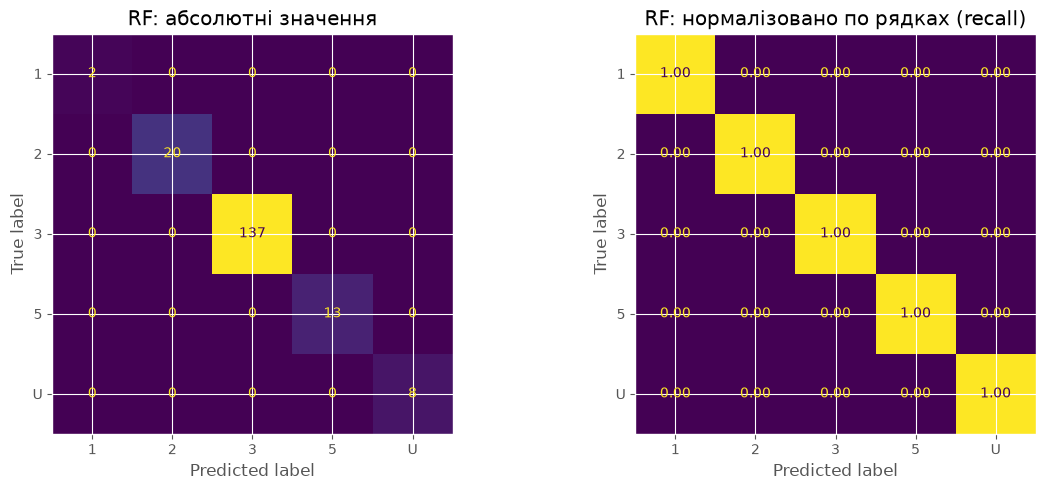

In [23]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

preds = {m: final[m].predict(X_test) for m in MODELS}
rows = {m: {'accuracy': round(accuracy_score(y_test, p), 3),
            'f1_macro': round(f1_score(y_test, p, average='macro'), 3),
            'balanced_acc': round(balanced_accuracy_score(y_test, p), 3)} for m, p in preds.items()}
print('Таблиця 6. Метрики на тесті')
display(pd.DataFrame(rows).T)

best_name = max(MODELS, key=lambda m: nested[m].mean())
print('Найкраща за nested CV:', best_name)
labels = list(range(len(ley.classes_)))
print(classification_report(y_test, preds[best_name], labels=labels,
                            target_names=[str(c) for c in ley.classes_], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, norm, title in zip(axes, [None, 'true'], ['абсолютні значення', 'нормалізовано по рядках (recall)']):
    cm = confusion_matrix(y_test, preds[best_name], labels=labels, normalize=norm)
    ConfusionMatrixDisplay(cm, display_labels=[str(c) for c in ley.classes_]).plot(
        ax=ax, colorbar=False, values_format='.2f' if norm else 'd')
    ax.set_title(f'{best_name}: {title}')
plt.tight_layout(); plt.show()

RF на тесті не робить жодної помилки, а DT і XGB мають дещо нижчі показники. Проте тест містить лише 180 об’єктів (клас 1 – 2 об’єкти, U – 8), тому 1,000 є оптимістичною й дуже грубою оцінкою. Відсутність значущої різниці RF vs DT (Таблиця 5) перевірялась лише для моделей із параметрами за замовчуванням, а не для налаштованих.

### 3.7 Важливість ознак: MDI vs permutation importance (top-15)
* **MDI** (`feature_importances_`) – рахується на train, зміщена до ознак з багатьма унікальними значеннями / після OHE розпорошена по дамі-колонках.
* **Permutation importance** – по `f1_macro` на тесті, 10 повторів, на цілому пайплайні (отже на **сирих** ознаках, без розпорошення OHE).

DT: індикаторів пропусків у MDI top-15: 3
RF: індикаторів пропусків у MDI top-15: 4
XGB: індикаторів пропусків у MDI top-15: 4


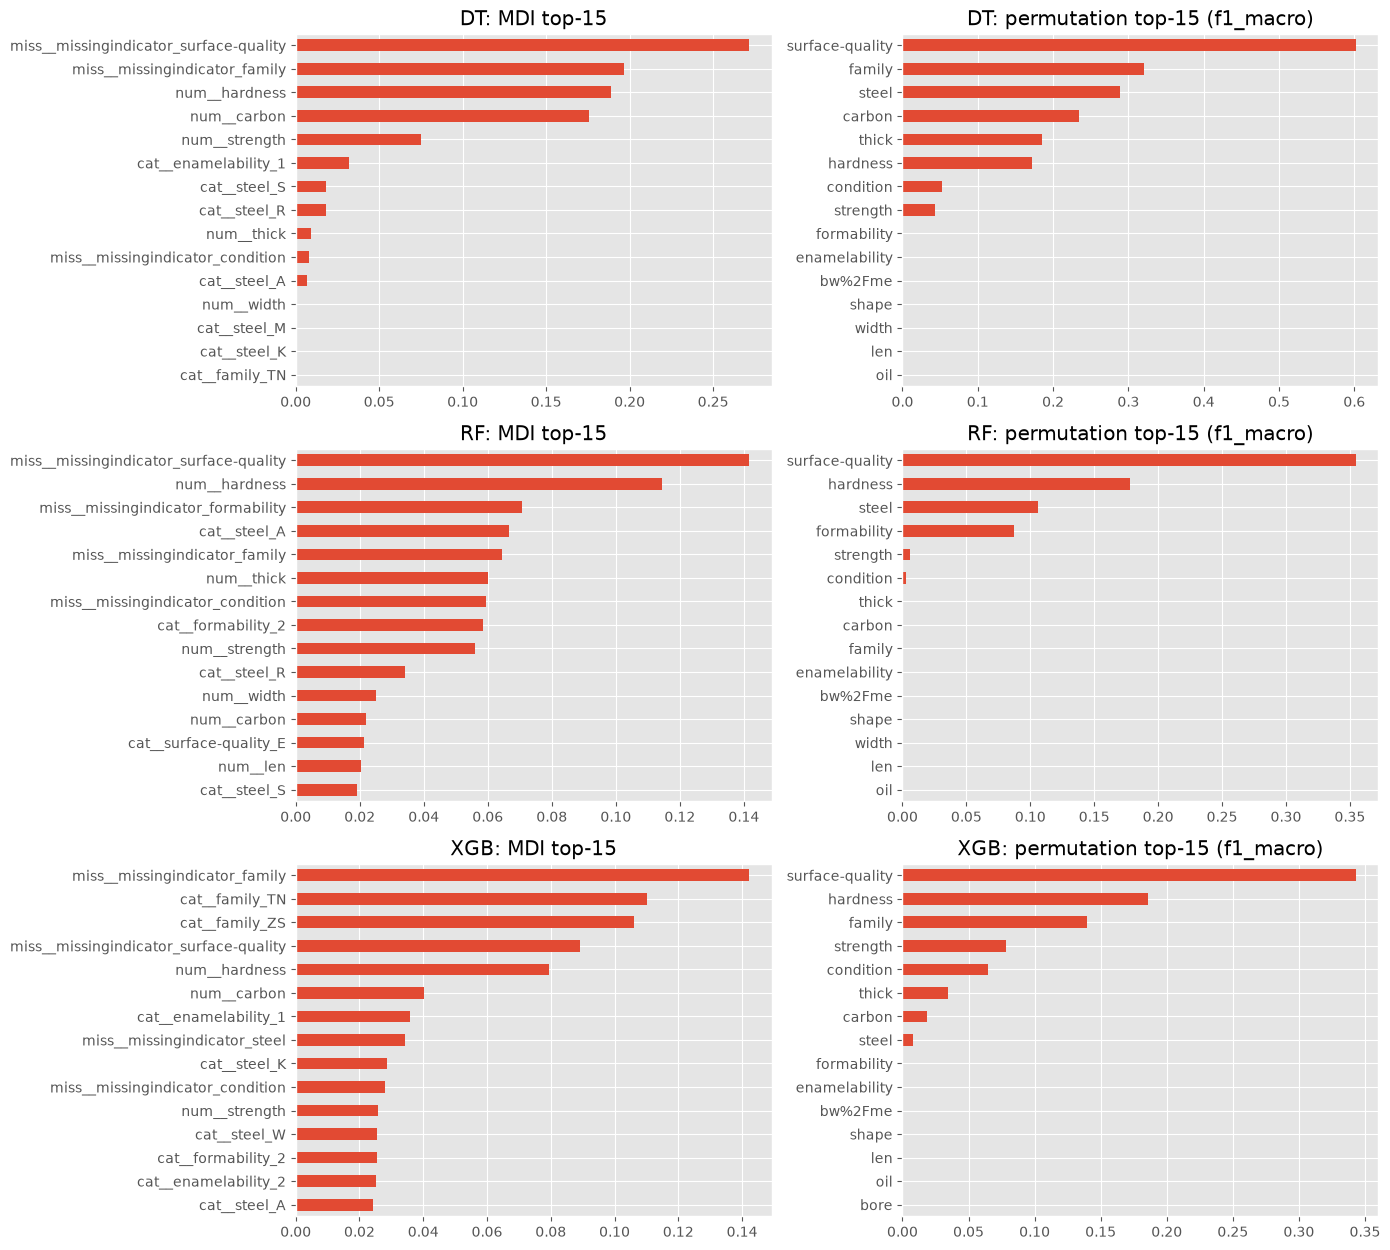

In [24]:
from sklearn.inspection import permutation_importance

def mdi_series(pipe):
    names = pipe.named_steps['prep'].get_feature_names_out()
    return pd.Series(pipe.named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)

perm = {}
fig, axes = plt.subplots(len(MODELS), 2, figsize=(14, 4.2*len(MODELS)))
for i, m_name in enumerate(MODELS):
    mdi = mdi_series(final[m_name]).head(15)
    pi = permutation_importance(final[m_name], X_test, y_test, scoring='f1_macro',
                                n_repeats=10, random_state=random_seed, n_jobs=1)
    perm[m_name] = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
    mdi[::-1].plot.barh(ax=axes[i, 0], title=f'{m_name}: MDI top-15')
    perm[m_name].head(15)[::-1].plot.barh(ax=axes[i, 1], title=f'{m_name}: permutation top-15 (f1_macro)')
    n_miss = sum(n.startswith('miss__') for n in mdi.index)
    print(f'{m_name}: індикаторів пропусків у MDI top-15: {n_miss}')
plt.tight_layout(); plt.show()

1) Збіжність MDI та permutation. Топи збігаються за змістом, але не за складом. Обидва методи виділяють surface-quality і hardness, а також (залежно від моделі) family, steel, carbon. MDI подає їх як окремі перетворені колонки (індикатор пропуску, one-hot, число), а permutation, застосована до всього пайплайну, перемішує початкову колонку цілком і агрегує ці внески. Є й розбіжності: у RF family і carbon у permutation близькі до нуля, хоча в MDI вони присутні; steel у permutation помітний, а в MDI розбитий на дрібні one-hot колонки; у XGB MDI ставить на перше місце family, а permutation – surface-quality. Для більшості ознак permutation importance дорівнює нулю, а великі значення для surface-quality зумовлені тим, що збурення цієї ознаки зачіпає рідкісні класи, які сильно впливають на macro F1 на малому тесті.

(2) Індикатори пропусків. Індикатори miss__* (surface-quality, family, formability, condition, steel) потрапили до топ-15 за MDI в усіх трьох моделях, причому часто на перші місця. Отже, сам факт пропуску несе інформацію про клас, тобто пропуски не є MCAR. Формальний тест (χ²/перестановковий) проводився лише для ознак із часткою пропусків понад 50 % (enamelability, oil, family, bw%2Fme; усі p < 0,01, для family p ≈ 5·10⁻⁹⁹). Для surface-quality, condition, formability і steel тест не робили, тому для них висновок спирається на важливість індикаторів і приріст macro F1 у варіанті B. Те, що в permutation найважливішими є ті самі початкові ознаки, підтверджує, що вони суттєві для прогнозу. Строго розрізнити MAR і MNAR за даними неможливо; імовірно, значна частина пропусків є структурною (ознака не застосовна до певного типу виробу), тому пропуск корелює з класом.

(3) Чому MDI може завищувати важливість. По-перше, MDI обчислюється на тренувальних даних і відображає те, що модель використала для розбиттів, а не внесок у якість на нових даних. По-друге, він зміщений на користь ознак із великою кількістю унікальних значень (числові ознаки мають багато можливих порогів). По-третє, важливість однієї початкової ознаки розподіляється між кількома колонками (one-hot steel_S, steel_R, steel_A…), тому окремі колонки виглядають слабшими, а числові й індикаторні сильнішими. По-четверте, при корельованих ознаках MDI ділить важливість між ними довільно. Permutation importance, обчислена на тесті, цих недоліків частково позбавлена, але при корельованих ознаках може занижувати важливість кожної з них.

### 3.8 Об’єкти, на яких моделі розходяться, та SHAP
Шукаємо об’єкти тесту, де передбачення DT, RF і XGB не збігаються. Якщо їх менше трьох, доповнюємо об’єктами з train (передбачення з `cross_val_predict`, тож вони out-of-fold).

In [25]:
from sklearn.model_selection import cross_val_predict

def disagreement_table(P, y_true, index, source):
    df = pd.DataFrame({m: ley.inverse_transform(p) for m, p in P.items()}, index=index)
    df.insert(0, 'true', ley.inverse_transform(y_true))
    df.insert(0, 'source', source)
    mask = df[list(MODELS)].nunique(axis=1) > 1
    return df[mask]

dis = disagreement_table(preds, y_test, X_test.index, 'test')
if len(dis) < 3:
    cvp = {m: cross_val_predict(build_pipeline(cls, True, studies[m].best_params), X_train, y_train,
                                cv=StratifiedKFold(5, shuffle=True, random_state=random_seed))
           for m, cls in MODELS.items()}
    dis = pd.concat([dis, disagreement_table(cvp, y_train, X_train.index, 'train (OOF)')])
dis = dis.head(max(3, min(len(dis), 8)))
print('Таблиця 7. Об’єкти з розбіжністю передбачень')
display(dis)

Таблиця 7. Об’єкти з розбіжністю передбачень


,source,true,DT,RF,XGB
17,test,U,3,U,3
453,test,U,3,U,U
746,train (OOF),3,3,2,2
24,train (OOF),1,2,3,3
585,train (OOF),3,2,3,2
870,train (OOF),U,3,U,3
406,train (OOF),1,1,1,3
827,train (OOF),3,3,2,2


Розбіжностей небагато: у тестовій вибірці знайдено лише 2 такі об'єкти (17, 453), тому, як і передбачено завданням, таблицю доповнено 6 об'єктами з тренувальної вибірки з out-of-fold прогнозами. Кількість розбіжностей мала, що відповідає ефекту стелі: усі три моделі переважно дають однакові прогнози, а відмінності зосереджені на рідкісних і межових об'єктах.

Серед 8 об'єктів RF вгадав клас у 5 випадках, DT у 3, XGB лише в 1, тож RF найменше помиляється. Проте вибірка надто мала (8 об'єктів, до того ж відібраних саме за розбіжністю), щоб робити статистичні висновки про перевагу моделей; це якісна ілюстрація, а не доказ.

Помітна закономірність за класами. Клас U (рідкісний) у трьох випадках із трьох правильно визначає RF, тоді як DT усі три рази помиляється, передбачаючи клас 3, а XGB помиляється двічі з трьох. Імовірно, жорсткі пороги одного дерева та послідовне виправлення залишків у бустингу схильні відносити рідкісний клас до більшого сусіднього класу (3), тоді як усереднення в RF стійкіше до цього. Об'єкт 24 (true = 1) усі моделі класифікували неправильно: це схоже на межовий або нетиповий об'єкт, де ознаки близькі до іншого класу. Класи 2 і 3 моделі плутають між собою (об'єкти 746, 827, 585), що вказує на схожість їхніх ознак.

Об'єкти з OOF-прогнозами беруться з тренувальної вибірки, тому вони можуть відрізнятися за складністю від тесту; це зазначено явно.

Об’єкт 17 (test), істинний клас: U


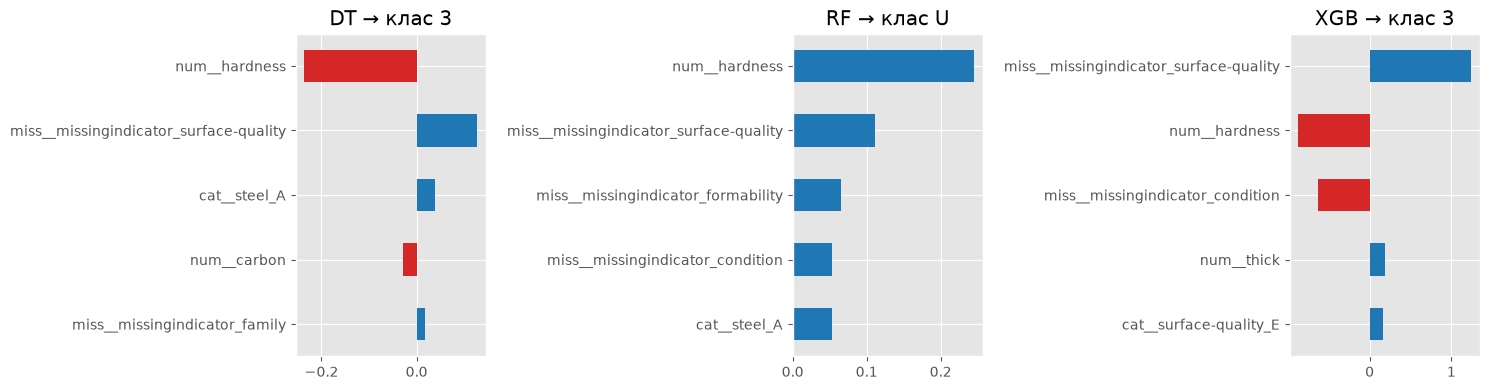

Таблиця 7b. Топ-5 ознак за SHAP для обраного об’єкта


,model,predicted,top-5 SHAP
0,DT,3,"num__hardness (-0.24; x=80), miss__missingindicator_surface-quality (+0.13; x=0), cat__steel_A (+0.04; x=1), num__carbon (-0.03; x=0), miss__missingindicator_family (+0.02; x=1)"
1,RF,U,"num__hardness (+0.25; x=80), miss__missingindicator_surface-quality (+0.11; x=0), miss__missingindicator_formability (+0.07; x=1), miss__missingindicator_condition (+0.05; x=1), cat__steel_A (+0.05; x=1)"
2,XGB,3,"miss__missingindicator_surface-quality (+1.24; x=0), num__hardness (-0.87; x=80), miss__missingindicator_condition (-0.63; x=1), num__thick (+0.19; x=0.8), cat__surface-quality_E (+0.16; x=0)"


In [ ]:
import shap

def explain_row(m_name, x_row, top=5):
    pipe = final[m_name]
    Xt = pipe.named_steps['prep'].transform(x_row)
    names = pipe.named_steps['prep'].get_feature_names_out()
    clf = pipe.named_steps['clf']
    c = int(clf.predict(Xt)[0])
    sv = shap.TreeExplainer(clf).shap_values(Xt)
    if isinstance(sv, list):         
        v = sv[c][0]
    else:                              
        sv = np.asarray(sv)
        v = sv[0, :, c] if sv.ndim == 3 else sv[0]
    s = pd.Series(v, index=names)
    return c, s.reindex(s.abs().sort_values(ascending=False).index).head(top), pd.Series(Xt[0], index=names)

obj_idx = dis.index[0]
src = dis.iloc[0]['source']
x_row = (X_test if src == 'test' else X_train).loc[[obj_idx]]
print(f'Об’єкт {obj_idx} ({src}), істинний клас: {dis.iloc[0]["true"]}')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rows = []
for ax, m_name in zip(axes, MODELS):
    c, top5, xt = explain_row(m_name, x_row)
    top5[::-1].plot.barh(ax=ax, color=['tab:red' if v < 0 else 'tab:blue' for v in top5[::-1]],
                         title=f'{m_name} → клас {ley.classes_[c]}')
    rows.append({'model': m_name, 'predicted': ley.classes_[c],
                 'top-5 SHAP': ', '.join(f'{n} ({v:+.2f}; x={xt[n]:.2g})' for n, v in top5.items())})
plt.tight_layout(); plt.show()
print('Таблиця 7b. Топ-5 ознак за SHAP для обраного об’єкта')
pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(rows))

Аналіз об'єкта 17 (true = U). RF правильно передбачив U, DT і XGB помилково вибрали клас 3. У всіх моделях найбільші внески дають hardness = 80 та індикатори пропусків (surface-quality, condition, formability), що підтверджує інформативність самого факту пропуску. Різниця в прогнозах зумовлена тим, як моделі використовують ті самі ознаки: у RF hardness та індикатори узгоджено підтримують клас U, а в XGB внесок missingindicator_surface-quality (+1,24) переважив від'ємний внесок hardness (−0,87) і змістив рішення до класу 3. У DT за модулем більший саме внесок hardness (−0,24, тобто проти класу 3), ніж індикатора surface-quality (+0,13), тож вибір класу 3 там визначили інші, менші внески, яких немає в top-5. Жорсткі пороги окремого дерева та послідовне виправлення залишків у бустингу схильні відносити рідкісний клас U до більшого сусіднього класу, тоді як усереднення в RF цьому протидіє. Малі за величиною внески в DT і RF вказують, що об'єкт лежить поблизу межі між U та 3 (це варто підтвердити за predict_proba). Величини SHAP між моделями порівнювати напряму не можна (різні шкали), лише знак і ранг ознак.

## Висновки

**Пропуски.** Для ознак із часткою пропусків понад 50 % (enamelability, oil, family, bw%2Fme) тест χ²/перестановковий відхиляє незалежність пропуску й класу (p від 4·10⁻⁴ до 8,5·10⁻³, для family – ≈5·10⁻⁹⁹), тобто пропуски не є MCAR. Для менш розріджених ознак (surface-quality, condition, formability, steel) тест не проводився, але їхні індикатори входять до топу важливості. MAR від MNAR за даними розрізнити неможливо; ймовірно, багато пропусків структурні (ознака незастосовна до типу виробу). Пропуски оброблено медіаною/модою з додаванням `MissingIndicator` (варіант B), а повністю порожні, константні й майже порожні колонки видалено.

**Індикатори пропусків.** Варіант B дає значущий приріст macro F1 за скоригованим t-тестом Надо–Бенжіо: DT +0,047 (p = 0,021), RF +0,061 (p < 0,0001), XGB +0,043 (p = 0,040); для XGB значущість межова.

**Найкраща модель.** RF найкращий за всіма оцінками: macro F1 0,959 ± 0,072 у CV (варіант B), 0,951 ± 0,086 у nested CV і 1,000 на тесті (DT 0,970, XGB 0,986). Але RF vs DT за замовчуванням значущо не відрізняються (p = 0,59), а nested CV для DT помітно нижчий (0,902 ± 0,124), хоча цю різницю окремо не тестували. Тест замалий (клас 1 – 2 об’єкти, U – 8), тому 1,000 не слід сприймати як реальну якість.

**Nested CV проти best_value.** Оптимістичність best_value виражена лише для DT (gap = 0,061), для RF вона мала (0,010), а для XGB gap від’ємний (−0,027), тобто best_value тут нижчий за nested. З урахуванням std ≈ 0,09 між зовнішніми фолдами gap для RF і XGB лежить у межах шуму.

**Гіперпараметри.** Найважливіші – min_samples_leaf (DT 0,69, RF 0,66) і min_child_weight (XGB 0,83), що узгоджується з дисбалансом: великі значення не дозволяють виділити рідкісні класи. Найкращі значення лежать на нижній межі діапазону (min_samples_leaf = 1, min_child_weight ≈ 1,01), тож для XGB діапазон варто розширити нижче 1.

**Помилки за класами.** Моделі плутають рідкісні класи 1 та U (а не 5, який на тесті має 13 об’єктів) і пару 2↔3. DT і XGB відносять U до більшого класу 3, RF стійкіший; об’єкт 24 (true = 1) неправильно класифікували всі три моделі. Вибірка з 8 розбіжних об’єктів надто мала для статистичних висновків.

**Важливість ознак і SHAP.** MDI і permutation збігаються за змістом (surface-quality, hardness, а також family, steel, carbon залежно від моделі), але не за складом: MDI розпорошує важливість по one-hot колонках і завищує індикатори, permutation агрегує по вихідних ознаках і ставить surface-quality на перше місце в усіх моделях. SHAP для об’єкта 17 показав, що рішення визначають hardness та індикатор surface-quality; у XGB індикатор переважив hardness, у DT рішення залежить від менших внесків поза top-5, а значення SHAP між моделями порівнювати можна лише за знаком і рангом.

**Обмеження.** Мало даних (898 об’єктів), сильний дисбаланс, дуже малий тест, лише 20 спроб Optuna на модель, t-тест RF vs DT зроблено для моделей без налаштування. Також видалення константних колонок разом із їхніми індикаторами пропусків (напр. temper_rolling, bf, bl) могло прибрати частину інформації.

**Рекомендація.** Обрати RF із варіантом B (індикатори пропусків) і налаштованими параметрами: він найкращий у CV, nested CV і на тесті та стійкіший за DT і XGB на рідкісних класах. DT можна лишити як інтерпретовану альтернативу, якщо важлива прозорість, але з нижчою якістю за nested CV.
